# Notebook 04 · Diagnostics et explicabilité (S9, exigence 8)

Le modèle final est la régression logistique calibrée (notebook 03). Le test a déjà été évalué une fois (notebook 03b) : ici, **on ne change plus rien**. On cherche à comprendre, dans l'ordre de S9 :

1. **où** le modèle se trompe : les slices ;
2. **ce qui** pilote ses prédictions : importance par permutation, puis SHAP global et local ;
3. **quelle forme** a l'effet appris : PDP et ICE ;
4. si l'hypothèse du notebook 03, l'inversion du signal des news après 2021, se vérifie mois par mois.

Rappel de S9 : SHAP et l'importance décrivent le **modèle**, pas le monde. Ils n'établissent aucune causalité.

La classe positive reste la **baisse** : une contribution positive pousse le modèle vers « le Nikkei va baisser ».

In [1]:
from pathlib import Path
import json
import warnings

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import shap
import yaml
from sklearn.metrics import average_precision_score, confusion_matrix, log_loss

warnings.filterwarnings("ignore")
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
CFG = yaml.safe_load(open(ROOT / "config.yaml"))
FIG, RUNS = ROOT / "figures", ROOT / "runs"
SEED = CFG["seed"]
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.3})

DEC = json.loads((RUNS / "decision_finale.json").read_text())
table = pd.read_csv(ROOT / CFG["data"]["model_table"], parse_dates=["date"]).set_index("date")
FEATURES = [c for g in ["news", "price", "macro", "fx"] for c in CFG["features"][g]]
REGIME = CFG["features"]["regime"]
COLONNES = FEATURES + [c for c in REGIME if c not in FEATURES]
PIPE = joblib.load(ROOT / DEC["fichiers_modeles"]["logit"])
A, C = DEC["platt"]["logit"]["a"], DEC["platt"]["logit"]["c"]

def p_baisse(X):
    f = PIPE.decision_function(X[COLONNES])           # log-odds brut de la baisse
    return 1 / (1 + np.exp(-(A * f + C)))              # Platt (notebook 03)

BLOCS = {"entraînement 2017-2021 (avec news)": table.loc["2017-04":"2021-12"],
         "validation 2022-2023": table[table["bloc"] == "validation"],
         "test 2024-2026": table[table["bloc"] == "test"]}
test = BLOCS["test 2024-2026"]
P_CONST = table.loc[table["bloc"] == "entraînement", "y_baisse"].mean()
print({k: len(v) for k, v in BLOCS.items()})

{'entraînement 2017-2021 (avec news)': 57, 'validation 2022-2023': 24, 'test 2024-2026': 33}


## 1. Slices : où le modèle se trompe-t-il ? (S9)

Un slice est une loupe : un bon score global peut cacher un échec sur un sous-groupe, et inversement. On regarde le test selon trois découpages.
- **Régime k-means** : le k-means de la pipeline, ajusté sur l'entraînement, classe chaque mois en calme ou agité.
- **Réunion de la BoJ le mois suivant** : oui ou non. Le calendrier est annoncé un an à l'avance, ce n'est donc pas une fuite.
- **Année du test**.

Pour chaque slice : les comptes (S9 : un score sans les comptes peut tromper), la prévalence, qui fixe la référence de PR-AUC du slice, la log-loss contre la constante, et le recall au seuil 0,5 avec son erreur type.

$$\widehat{SE}(\widehat R)\approx\sqrt{\frac{\widehat R(1-\widehat R)}{n_+}}$$

In [2]:
regime_pipe = PIPE.named_steps["prep"].named_transformers_["regime"]
centres = pd.DataFrame(regime_pipe.named_steps["scale"].inverse_transform(regime_pipe.named_steps["kmeans"].cluster_centers_), columns=REGIME)
agite = int(centres["vix"].idxmax())
nom_regime = {agite: "agité", 1 - agite: "calme"}
print("centres du k-means (unités d'origine) :")
display(centres.rename(index=nom_regime).round(3))

def regime_de(X):
    return pd.Series(regime_pipe.predict(X[REGIME]), index=X.index).map(nom_regime)

def diagnostic_slice(d):
    y = d["y_baisse"].astype(int)
    p = p_baisse(d)
    yhat = (p >= 0.5).astype(int)
    tn, fp, fn, tp = confusion_matrix(y, yhat, labels=[0, 1]).ravel()
    n_pos = int(y.sum())
    rec = tp / n_pos if n_pos else np.nan
    return {"mois": len(d), "baisses": n_pos, "prévalence": y.mean(), "TP": tp, "FP": fp, "FN": fn, "TN": tn,
            "recall (τ = 0,5)": rec, "erreur type du recall": np.sqrt(rec * (1 - rec) / n_pos) if n_pos else np.nan,
            "PR-AUC": average_precision_score(y, p) if 0 < n_pos < len(d) else np.nan,
            "log-loss modèle": log_loss(y, p, labels=[0, 1]),
            "log-loss constante": log_loss(y, np.full(len(d), P_CONST), labels=[0, 1])}

t = test.copy()
t["régime"] = regime_de(t)
t["réunion BoJ le mois suivant"] = np.where(t["boj_meeting_next_month"] > 0, "oui", "non")
t["année"] = t.index.year.astype(str)
lignes = {("ensemble du test", "tous"): diagnostic_slice(t)}
for coupe in ["régime", "réunion BoJ le mois suivant", "année"]:
    for valeur, d in t.groupby(coupe):
        lignes[(coupe, valeur)] = diagnostic_slice(d)
SLICES = pd.DataFrame(lignes).T
SLICES.round(3)

centres du k-means (unités d'origine) :


,n225_vol_ewma,n225_ret_1m,vix
agité,0.283,-0.045,27.300
calme,0.171,0.024,15.635


mois  baisses  prévalence   TP    FP   FN  \
ensemble du test            tous   33.0     12.0       0.364  9.0  11.0  3.0   
régime                      agité   9.0      3.0       0.333  2.0   2.0  1.0   
                            calme  24.0      9.0       0.375  7.0   9.0  2.0   
réunion BoJ le mois suivant non    11.0      4.0       0.364  3.0   4.0  1.0   
                            oui    22.0      8.0       0.364  6.0   7.0  2.0   
année                       2024   12.0      6.0       0.500  6.0   3.0  0.0   
                            2025   12.0      3.0       0.250  1.0   3.0  2.0   
                            2026    9.0      3.0       0.333  2.0   5.0  1.0   

                                     TN  recall (τ = 0,5)  \
ensemble du test            tous   10.0             0.750   
régime                      agité   4.0             0.667   
                            calme   6.0             0.778   
réunion BoJ le mois suivant non     3.0             0.750   
                            oui     7.0             0.750   
année                       2024    3.0             1.000   
                            2025    6.0             0.333   
                            2026    1.0             0.667   

                                   erreur type du recall  PR-AUC  \
ensemble du test            tous                   0.125   0.420   
régime                      agité                  0.272   0.643   
                            calme                  0.139   0.422   
réunion BoJ le mois suivant non                    0.217   0.399   
                            oui                    0.153   0.456   
année                       2024                   0.000   0.704   
                            2025                   0.272   0.350   
                            2026                   0.272   0.356   

                                   log-loss modèle  log-loss constante  
ensemble du test            tous             0.708               0.657  
régime                      agité            0.660               0.644  
                            calme            0.725               0.662  
réunion BoJ le mois suivant non              0.743               0.657  
                            oui              0.690               0.657  
année                       2024             0.672               0.717  
                            2025             0.684               0.607  
                            2026             0.787               0.644

## 2. Importance par permutation (S9)

On mélange une variable entre les mois et on mesure de combien la log-loss se dégrade. C'est l'expérience de S9, moyennée sur 50 tirages. Avec la log-loss, où plus bas est mieux :

$$I^{\text{perm}}_j=\frac{1}{R}\sum_{r=1}^{R}\left(\text{log-loss}_{\text{shuffle}(j),r}-\text{log-loss}_{\text{base}}\right)$$

Une importance **positive** veut dire que la variable aide sur ce bloc. Une importance **négative** veut dire que le modèle ferait mieux sans elle : il s'appuie sur une relation qui ne tient plus. On la calcule sur trois blocs avec news (2017-2021, validation, test), pour voir ce qui change. Le piège de S9 est que des variables corrélées se substituent l'une à l'autre. On permute donc aussi deux groupes ensemble : les deux momentums, et les trois variables de risque du k-means.

,entraînement 2017-2021 (avec news),validation 2022-2023,test 2024-2026
news_attention_6m,0.0396,-0.0207,0.0184
"groupe risque (vol, rendement du mois, VIX)",0.0135,0.0036,-0.0007
groupe momentums (3 et 12 mois),0.0122,0.0152,0.0058
n225_mom_12m,0.0102,0.0154,0.0121
n225_ret_1m,0.0075,-0.0005,0.0017
vix,0.0042,-0.0002,0.0002
n225_vol_ewma,0.0031,0.0040,-0.0044
n225_mom_3m,0.0010,-0.0020,-0.0016
d_jgb10y_bp,0.0008,0.0023,-0.0271
news_sent_w,0.0005,-0.0031,0.0025


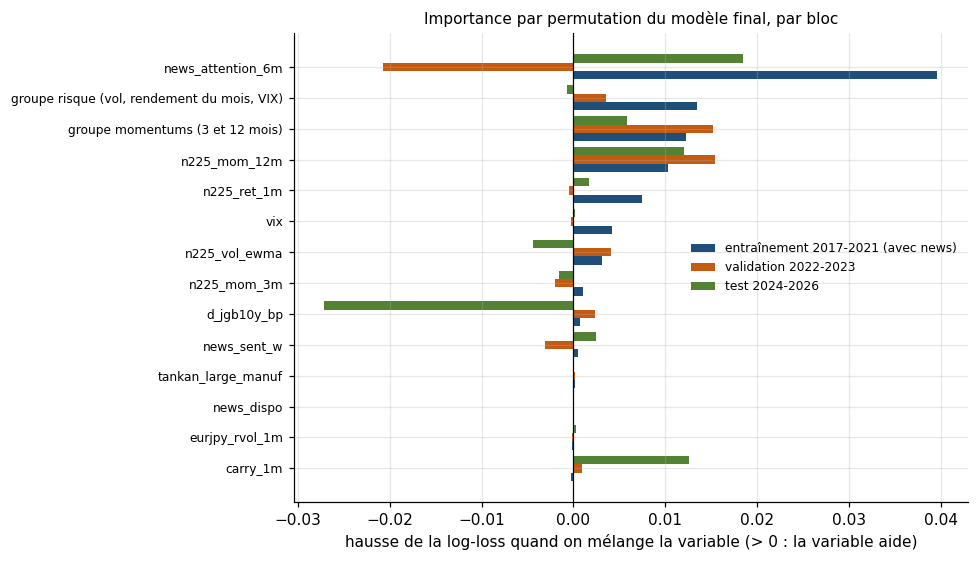

In [3]:
rng = np.random.default_rng(SEED)
GROUPES = {c: [c] for c in COLONNES}
GROUPES["groupe momentums (3 et 12 mois)"] = ["n225_mom_3m", "n225_mom_12m"]
GROUPES["groupe risque (vol, rendement du mois, VIX)"] = REGIME

def importance_permutation(d, R=50):
    y = d["y_baisse"].astype(int)
    base = log_loss(y, p_baisse(d), labels=[0, 1])
    out = {}
    for nom, cols in GROUPES.items():
        deltas = []
        for _ in range(R):
            dp = d.copy()
            ordre = rng.permutation(len(d))
            dp[cols] = d[cols].to_numpy()[ordre]
            deltas.append(log_loss(y, p_baisse(dp), labels=[0, 1]) - base)
        out[nom] = np.mean(deltas)
    return pd.Series(out)

PERM = pd.DataFrame({nom: importance_permutation(d) for nom, d in BLOCS.items()})
PERM = PERM.sort_values("entraînement 2017-2021 (avec news)", ascending=False)
display(PERM.round(4))

fig, ax = plt.subplots(figsize=(9, 5.2))
ordre = PERM.index[::-1]
y_pos = np.arange(len(ordre))
for k, (nom, couleur) in enumerate(zip(PERM.columns, ["#1f4e79", "#c55a11", "#548235"])):
    ax.barh(y_pos + (k - 1) * 0.27, PERM.loc[ordre, nom], height=0.27, color=couleur, label=nom)
ax.set_yticks(y_pos, ordre, fontsize=8)
ax.axvline(0, color="black", lw=0.8)
ax.set_xlabel("hausse de la log-loss quand on mélange la variable (> 0 : la variable aide)")
ax.set_title("Importance par permutation du modèle final, par bloc", fontsize=10)
ax.legend(frameon=False, fontsize=8)
fig.tight_layout()
fig.savefig(FIG / "04_permutation.png")
plt.show()

## 3. SHAP : expliquer chaque prédiction (S9)

Pour un modèle linéaire, la valeur SHAP de la variable *j* a une forme simple : son poids fois l'écart de la variable standardisée à sa moyenne d'entraînement. Les contributions s'additionnent exactement jusqu'au score du mois :

$$\phi_j(x)=w_j\,\big(z_j-\mathbb{E}[z_j]\big),\qquad f(x)=\mathbb{E}[f]+\sum_j \phi_j(x)$$

Ici *f* est le **log-odds brut de la baisse**, avant Platt. La probabilité calibrée est σ(a·f + c), avec a = 0,92 : chaque contribution est donc à multiplier par 0,92 pour passer au log-odds calibré.

additivité : écart max entre la somme des contributions et le score du modèle = 3.3e-16


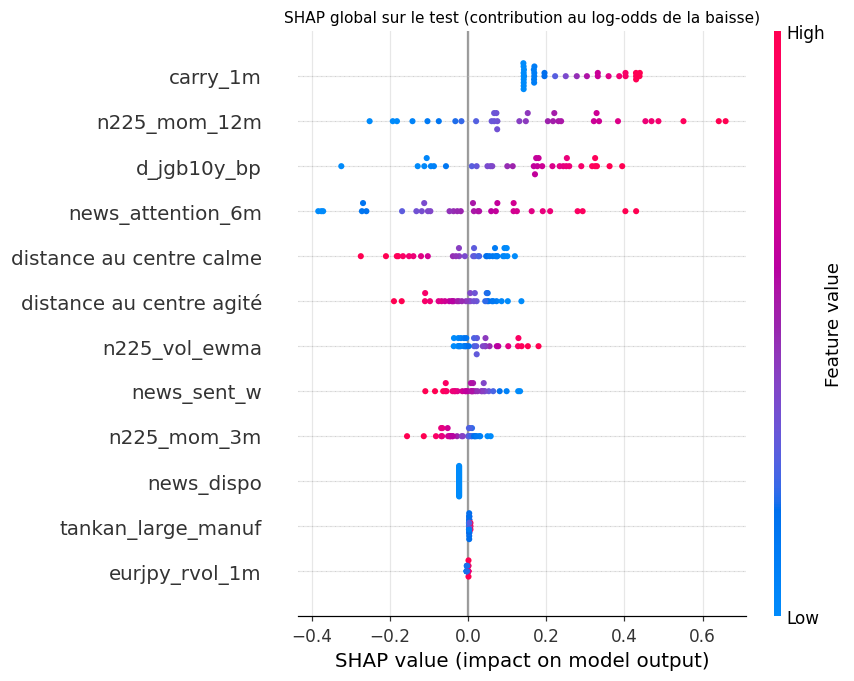

In [4]:
prep_scale = PIPE[:-1]
modele = PIPE.named_steps["model"]
NOMS_SORTIE = FEATURES + ["distance au centre calme", "distance au centre agité"] if agite == 1 else \
              FEATURES + ["distance au centre agité", "distance au centre calme"]
fond = prep_scale.transform(table.loc[table["bloc"] == "entraînement", COLONNES])
explainer = shap.LinearExplainer(modele, fond)

def expliquer(d):
    e = explainer(prep_scale.transform(d[COLONNES]))
    e.feature_names = NOMS_SORTIE
    e.data = PIPE.named_steps["prep"].transform(d[COLONNES])   # valeurs d'origine pour l'affichage
    return e

E_test = expliquer(test)
verif = np.abs(E_test.base_values + E_test.values.sum(axis=1) - PIPE.decision_function(test[COLONNES])).max()
print(f"additivité : écart max entre la somme des contributions et le score du modèle = {verif:.1e}")

plt.figure()
shap.plots.beeswarm(E_test, max_display=12, show=False)
plt.title("SHAP global sur le test (contribution au log-odds de la baisse)", fontsize=10)
plt.tight_layout()
plt.savefig(FIG / "04_shap_beeswarm_test.png", bbox_inches="tight")
plt.show()

In [5]:
moyenne_abs = pd.DataFrame({nom: pd.Series(np.abs(expliquer(d).values).mean(axis=0), index=NOMS_SORTIE)
                            for nom, d in BLOCS.items()})
moyenne_signee = pd.DataFrame({nom: pd.Series(expliquer(d).values.mean(axis=0), index=NOMS_SORTIE)
                               for nom, d in BLOCS.items()})
print("Moyenne de |SHAP| par bloc (taille de l'effet) :")
display(moyenne_abs.sort_values("test 2024-2026", ascending=False).round(3))
print("Moyenne signée de SHAP par bloc (> 0 : la variable a poussé vers « baisse » en moyenne) :")
display(moyenne_signee.loc[moyenne_abs.sort_values("test 2024-2026", ascending=False).index].round(3))

Moyenne de |SHAP| par bloc (taille de l'effet) :


,entraînement 2017-2021 (avec news),validation 2022-2023,test 2024-2026
carry_1m,0.035,0.224,0.250
n225_mom_12m,0.121,0.132,0.231
d_jgb10y_bp,0.058,0.115,0.187
news_attention_6m,0.215,0.175,0.164
distance au centre calme,0.076,0.054,0.086
distance au centre agité,0.068,0.064,0.059
n225_vol_ewma,0.042,0.023,0.047
news_sent_w,0.053,0.038,0.044
n225_mom_3m,0.026,0.023,0.039
news_dispo,0.023,0.023,0.023


Moyenne signée de SHAP par bloc (> 0 : la variable a poussé vers « baisse » en moyenne) :


,entraînement 2017-2021 (avec news),validation 2022-2023,test 2024-2026
carry_1m,-0.035,0.198,0.250
n225_mom_12m,-0.005,-0.080,0.170
d_jgb10y_bp,0.017,0.052,0.132
news_attention_6m,-0.020,0.049,-0.006
distance au centre calme,-0.003,0.004,-0.014
distance au centre agité,-0.016,0.031,-0.009
n225_vol_ewma,-0.013,-0.010,0.032
news_sent_w,-0.010,0.021,0.008
n225_mom_3m,-0.001,0.001,-0.022
news_dispo,-0.023,-0.023,-0.023


**Explications locales (waterfall).** Quatre mois choisis pour leur intérêt, et non pour leur résultat :
- **fin juillet 2024**, qui prédit août 2024 : le mois du krach du 5 août ;
- **fin mars 2025**, qui prédit avril 2025 : le choc des droits de douane ;
- **fin septembre 2026**, le dernier mois du test ;
- **fin octobre 2026**, la ligne à prédire (le signal de novembre 2026).

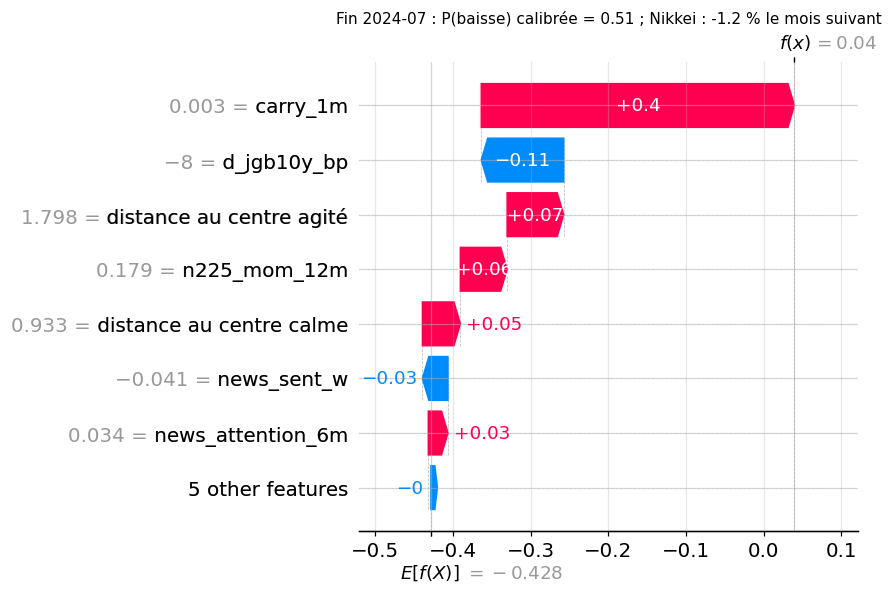

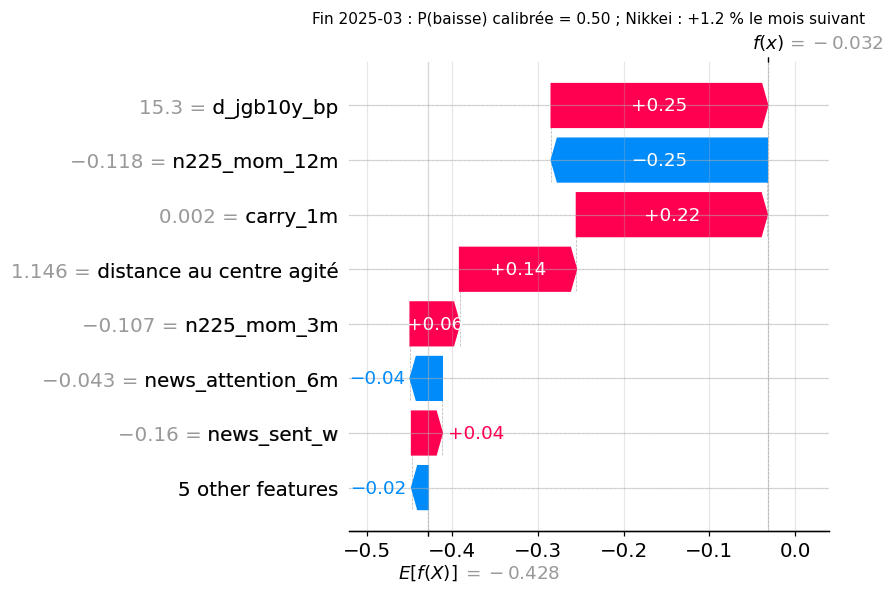

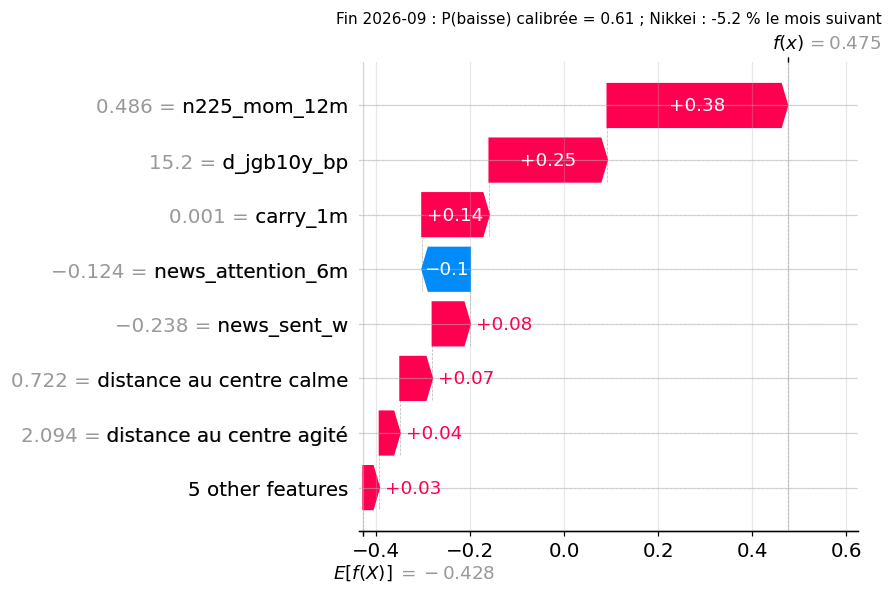

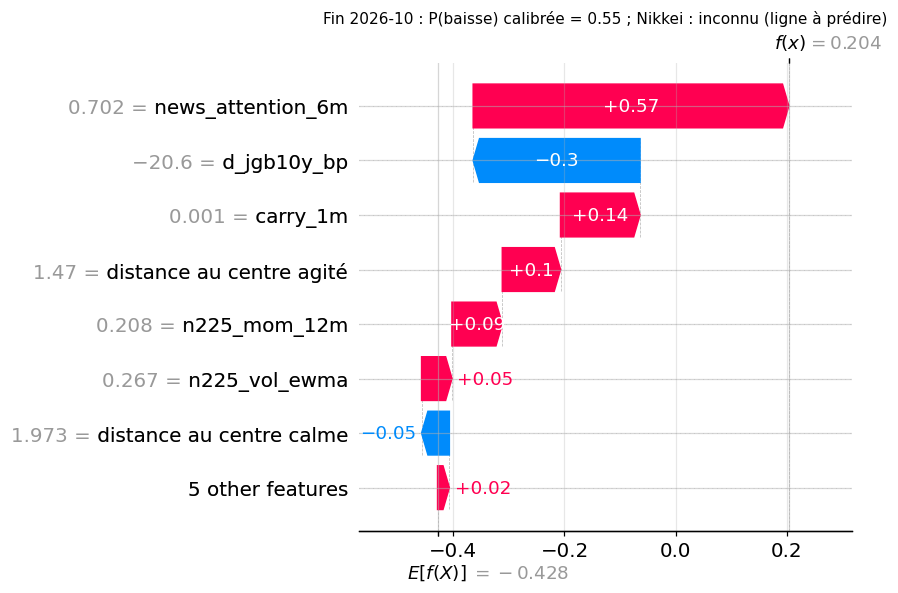

In [6]:
MOIS = ["2024-07-31", "2025-03-31", "2026-09-30", "2026-10-30"]
lignes_locales = table.loc[[pd.Timestamp(m) for m in MOIS]]
E_loc = expliquer(lignes_locales)
for i, m in enumerate(MOIS):
    d = lignes_locales.iloc[[i]]
    p = p_baisse(d)[0]
    suite = d["target_rn_next"].iloc[0]
    resultat = "inconnu (ligne à prédire)" if np.isnan(suite) else f"{100 * suite:+.1f} % le mois suivant"
    plt.figure()
    shap.plots.waterfall(E_loc[i], max_display=8, show=False)
    plt.title(f"Fin {m[:7]} : P(baisse) calibrée = {p:.2f} ; Nikkei : {resultat}", fontsize=10)
    plt.tight_layout()
    plt.savefig(FIG / f"04_shap_waterfall_{m[:7]}.png", bbox_inches="tight")
    plt.show()

## 4. L'hypothèse de l'inversion du signal, mois par mois

Le notebook 03 a vu le volume anormal d'articles changer de signe entre l'entraînement et la validation. On le vérifie de manière continue : la corrélation de rang entre le volume anormal du mois et le rendement du mois suivant, calculée sur une fenêtre glissante de 24 mois.

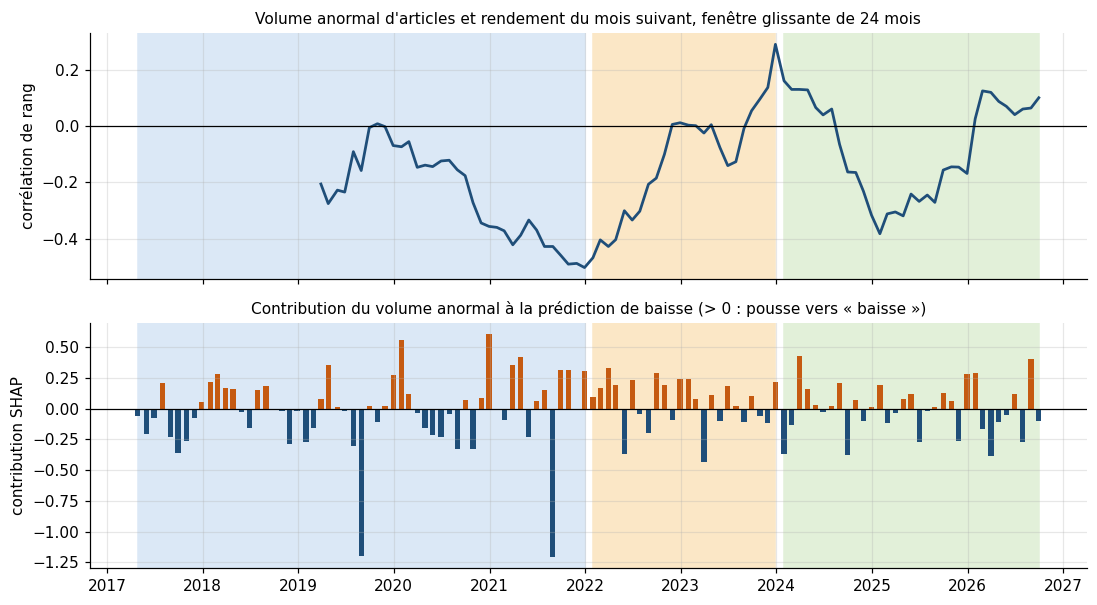

corrélation glissante moyenne par bloc :
bloc
entraînement   -0.25
test           -0.08
validation     -0.12


In [7]:
serie = table.loc["2017-04":"2026-09", ["news_attention_6m", "target_rn_next"]].dropna()
glissante = pd.Series({serie.index[i]: serie.iloc[i - 23:i + 1].corr(method="spearman").iloc[0, 1]
                       for i in range(23, len(serie))})

contrib_news = pd.Series(expliquer(table.loc["2017-04":"2026-09"]).values[:, NOMS_SORTIE.index("news_attention_6m")],
                         index=table.loc["2017-04":"2026-09"].index)

fig, axes = plt.subplots(2, 1, figsize=(10, 5.6), sharex=True)
couleurs = {"entraînement": "#dbe8f6", "validation": "#fbe7c6", "test": "#e2f0d9"}
for ax in axes:
    for bloc, coul in couleurs.items():
        idx = table.index[table["bloc"] == bloc]
        ax.axvspan(max(idx.min(), pd.Timestamp("2017-04-30")), idx.max(), color=coul, zorder=0)
axes[0].plot(glissante.index, glissante, color="#1f4e79", lw=1.8)
axes[0].axhline(0, color="black", lw=0.8)
axes[0].set_ylabel("corrélation de rang")
axes[0].set_title("Volume anormal d'articles et rendement du mois suivant, fenêtre glissante de 24 mois", fontsize=10)
axes[1].bar(contrib_news.index, contrib_news, width=20, color=np.where(contrib_news > 0, "#c55a11", "#1f4e79"))
axes[1].axhline(0, color="black", lw=0.8)
axes[1].set_ylabel("contribution SHAP")
axes[1].set_title("Contribution du volume anormal à la prédiction de baisse (> 0 : pousse vers « baisse »)", fontsize=10)
fig.tight_layout()
fig.savefig(FIG / "04_inversion_signal_news.png")
plt.show()

print("corrélation glissante moyenne par bloc :")
print(glissante.groupby(table.loc[glissante.index, "bloc"]).mean().round(2).to_string())

## 4b. Extrapolation : des variables hors de leur domaine d'entraînement

Le SHAP signé montre que, sur le test, le **portage** et la **variation du JGB 10 ans** poussent en moyenne vers « baisse », ce qu'ils ne faisaient pas sur l'entraînement. Depuis que les taux européens et japonais se sont écartés (2022) puis que la BoJ a remonté ses taux (2024-2025), ces variables prennent des valeurs que le modèle n'a jamais vues. On mesure cet écart en nombre d'écarts-types de l'entraînement.

In [8]:
tr = table[table["bloc"] == "entraînement"]
lignes = []
for c in ["carry_1m", "d_jgb10y_bp", "n225_mom_12m", "news_attention_6m"]:
    mu, sd = tr[c].mean(), tr[c].std()
    z_tr = ((tr[c] - mu) / sd).abs().max()
    for nom in ["validation 2022-2023", "test 2024-2026"]:
        z = (BLOCS[nom][c] - mu) / sd
        lignes.append({"variable": c, "bloc": nom, "z moyen": z.mean(), "|z| maximal": z.abs().max(),
                       "|z| maximal à l'entraînement": z_tr})
pd.DataFrame(lignes).set_index(["variable", "bloc"]).round(1)

z moyen  |z| maximal  \
variable          bloc                                         
carry_1m          validation 2022-2023      4.8         10.7   
                  test 2024-2026            6.0         10.5   
d_jgb10y_bp       validation 2022-2023      0.5          3.2   
                  test 2024-2026            1.2          3.7   
n225_mom_12m      validation 2022-2023     -0.3          1.2   
                  test 2024-2026            0.9          3.3   
news_attention_6m validation 2022-2023      0.2          1.3   
                  test 2024-2026            0.0          1.4   

                                        |z| maximal à l'entraînement  
variable          bloc                                                
carry_1m          validation 2022-2023                           3.5  
                  test 2024-2026                                 3.5  
d_jgb10y_bp       validation 2022-2023                           4.4  
                  test 2024-2026                                 4.4  
n225_mom_12m      validation 2022-2023                           2.8  
                  test 2024-2026                                 2.8  
news_attention_6m validation 2022-2023                           3.7  
                  test 2024-2026                                 3.7

**Le portage est en moyenne à 6 écarts-types de sa moyenne d'entraînement sur le test**, alors qu'il n'a jamais dépassé 3,5 pendant l'entraînement. Son coefficient est petit (+0,04 par écart-type), mais multiplié par 6 il ajoute environ 0,25 au log-odds de la baisse, chaque mois. C'est de l'**extrapolation** : un modèle linéaire prolonge sans limite une pente apprise sur un intervalle étroit.

**Une limite de l'importance par permutation (S9).** Mélanger le portage *entre les mois du test* garde son niveau élevé : la permutation ne voit donc pas ce décalage de niveau. SHAP le voit, parce qu'il compare chaque mois à la moyenne de l'entraînement.

**Test de l'hypothèse, après coup.** On recalcule la log-loss en ramenant le portage et la variation du JGB dans leur domaine d'entraînement (bornés au minimum et au maximum observés). **C'est un diagnostic, pas un nouveau modèle** : il ne change aucune décision et ne doit pas être présenté comme un score du projet, puisque le test a déjà été utilisé.

In [9]:
def borne(d, colonnes):
    d = d.copy()
    for c in colonnes:
        d[c] = d[c].clip(tr[c].min(), tr[c].max())
    return d

lignes = {}
for nom in ["validation 2022-2023", "test 2024-2026"]:
    d = BLOCS[nom]
    y = d["y_baisse"].astype(int)
    lignes[nom] = {"modèle tel quel": log_loss(y, p_baisse(d), labels=[0, 1]),
                   "portage borné": log_loss(y, p_baisse(borne(d, ["carry_1m"])), labels=[0, 1]),
                   "portage et JGB bornés": log_loss(y, p_baisse(borne(d, ["carry_1m", "d_jgb10y_bp"])), labels=[0, 1]),
                   "constante": log_loss(y, np.full(len(d), P_CONST), labels=[0, 1]),
                   "P(baisse) moyenne, portage et JGB bornés": p_baisse(borne(d, ["carry_1m", "d_jgb10y_bp"])).mean(),
                   "fréquence réelle": y.mean()}
pd.DataFrame(lignes).T.round(3)

,modèle tel quel,portage borné,portage et JGB bornés,constante,"P(baisse) moyenne, portage et JGB bornés",fréquence réelle
validation 2022-2023,0.699,0.700,0.700,0.681,0.436,0.417
test 2024-2026,0.708,0.704,0.704,0.657,0.499,0.364


## 5. PDP et ICE : la forme de l'effet appris (S9)

La dépendance partielle (PDP) fait varier le volume anormal d'articles sur une grille, toutes les autres variables restant celles de chaque mois du test, puis moyenne la probabilité calibrée de baisse. Les courbes ICE montrent la même chose mois par mois. Pour une logistique, l'effet est monotone par construction : la PDP montre surtout son ampleur en probabilité. Le piège de S9 : la PDP crée des combinaisons de variables peu réalistes quand les variables sont corrélées.

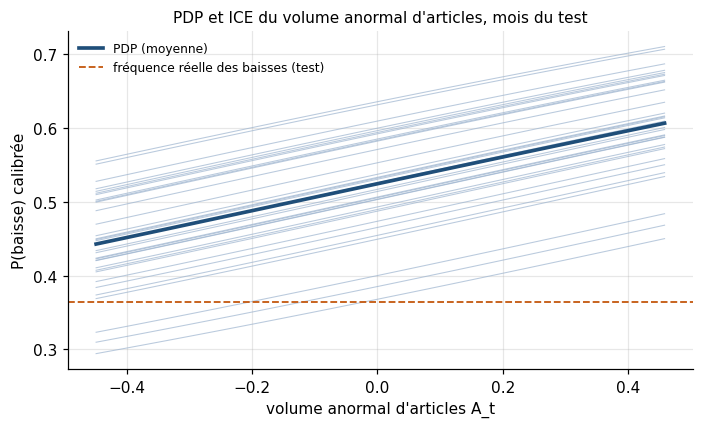

P(baisse) moyenne : 0.44 au 5e centile du volume, 0.61 au 95e


In [10]:
grille = np.linspace(table["news_attention_6m"].quantile(0.05), table["news_attention_6m"].quantile(0.95), 25)
ice = np.empty((len(test), len(grille)))
for k, v in enumerate(grille):
    d = test.copy()
    d["news_attention_6m"] = v
    ice[:, k] = p_baisse(d)

fig, ax = plt.subplots(figsize=(6.5, 4))
for ligne in ice:
    ax.plot(grille, ligne, color="#9db4cf", lw=0.7, alpha=0.7)
ax.plot(grille, ice.mean(axis=0), color="#1f4e79", lw=2.4, label="PDP (moyenne)")
ax.axhline(test["y_baisse"].mean(), color="#c55a11", ls="--", lw=1.2, label="fréquence réelle des baisses (test)")
ax.set_xlabel("volume anormal d'articles A_t")
ax.set_ylabel("P(baisse) calibrée")
ax.set_title("PDP et ICE du volume anormal d'articles, mois du test", fontsize=10)
ax.legend(frameon=False, fontsize=8)
fig.tight_layout()
fig.savefig(FIG / "04_pdp_ice_news.png")
plt.show()
print(f"P(baisse) moyenne : {ice[:, 0].mean():.2f} au 5e centile du volume, {ice[:, -1].mean():.2f} au 95e")

## 6. Ce qu'on retient (exigence 8)

- **Slices (S9).** Sur le test, le modèle ne bat la constante qu'en **2024** : log-loss 0,672 contre 0,717, les 6 baisses de l'année détectées au seuil 0,5, PR-AUC 0,70. Il échoue en 2025 et en 2026. Les écarts entre régimes, ou selon qu'il y a une réunion de la BoJ, restent dans le bruit : avec 3 à 9 baisses par slice, l'erreur type du recall vaut de 0,14 à 0,27.
- **Ce que le modèle a appris** (permutation sur l'entraînement 2017-2021). Le volume anormal d'articles est de loin la variable la plus utile : la log-loss monte de 0,040 quand on la mélange. Suivent le groupe des variables de risque (+0,014) et les momentums (+0,012). Les variables macro et de change n'apportent presque rien.
- **Ce qui a tenu, et ce qui a cassé.**
    - Le signal des news est **instable**, pas définitivement inversé. Il nuit sur la validation (−0,021) mais aide de nouveau sur le test (+0,018). Sa corrélation glissante oscille : −0,5 fin 2021, +0,3 fin 2023, −0,4 début 2025, +0,1 en 2026.
    - Le momentum 12 mois aide sur les trois blocs (+0,010 à +0,015).
    - La variation du JGB 10 ans est la variable qui nuit le plus sur le test (−0,027) : la BoJ remonte ses taux pendant que le marché monte.
- **D'où vient le pessimisme du test (SHAP signé).** Trois variables poussent en moyenne vers « baisse » :
    - le portage (+0,25 de log-odds) ;
    - le momentum 12 mois (+0,17), un pari contrarien contre une tendance qui dure ;
    - le JGB (+0,13).

    Le portage est à 6 écarts-types de sa moyenne d'entraînement : le modèle extrapole. Mais le ramener dans son domaine ne corrige presque rien (log-loss 0,708 → 0,704). L'extrapolation n'est donc qu'une partie de l'explication.
- **Sens business des variables importantes (exigence 8).**
    - *Volume anormal d'articles* : cohérent avec l'idée qu'un pic de news traduit du stress. Mais le lien dépend du type de nouvelles : du stress jusqu'en 2021, une normalisation monétaire ensuite.
    - *Momentum contrarien* : cohérent avec les rebonds en V de 2018-2021, pas avec une tendance durable comme celle de 2024-2026.
    - *Portage et JGB* : un portage élevé et des taux japonais en hausse peuvent annoncer une remontée du yen, qui pèse sur les exportateurs. Mais ces variables sont sorties de leur domaine historique, et le modèle les lit au-delà de ce qu'il a appris.
    - *Sentiment FinBERT* : presque aucun poids, ce qui confirme le notebook 01.
- **Rappel de S9.** Tout cela décrit le modèle, pas l'économie : SHAP n'établit aucune causalité.
- **Une leçon de méthode.** L'importance par permutation ne voit pas un décalage de niveau : elle mélange les valeurs à l'intérieur d'un bloc où elles sont toutes élevées. SHAP, qui compare chaque mois à la moyenne de l'entraînement, le voit.

**Pistes, non testées.** Elles ne pourront être évaluées honnêtement que sur des données postérieures à septembre 2026 :
- standardiser certaines variables sur une fenêtre glissante plutôt que sur l'entraînement fixe (par exemple, le portage en écart à sa moyenne récente) ;
- retirer ou borner les variables de taux ;
- recalibrer en continu.
